In [4]:
import  pandas as pd
import numpy   as np
import os
import glob
import sqlite3
import matplotlib.pyplot as plt
data_path = './data/'

csv_files = glob.glob(data_path + '*.csv')
dataframe={}
for file in csv_files:
    name= os.path.basename(file).replace(".csv","")
    dataframe[name] = pd.read_csv(file)
    #提取商品表和订单商品明细表
products = dataframe["olist_products_dataset"]
items = dataframe["olist_order_items_dataset"]

products_data = pd.merge(
    items,
    products,
    on = "product_id",
    how = "left"
)


In [13]:
#统计各类别的销售额
category_sales = products_data.groupby(
    "product_category_name",
)["price"].sum()

#计算各类别占比
category_sales_rate = (
        (category_sales / category_sales.sum()) *100
)
# 排序
category_sales_rate = category_sales_rate.sort_values(
    ascending =  False
)
category_sales_rate.head(10)

product_category_name
beleza_saude              9.384664
relogios_presentes        8.984461
cama_mesa_banho           7.731735
esporte_lazer             7.366843
informatica_acessorios    6.799485
moveis_decoracao          5.441072
cool_stuff                4.736696
utilidades_domesticas     4.714014
automotivo                4.419291
ferramentas_jardim        3.618048
Name: price, dtype: float64

In [14]:
#计算累计销售额占比
category_cum_rate = category_sales_rate.cumsum()
print(category_cum_rate.head(10))

product_category_name
beleza_saude               9.384664
relogios_presentes        18.369125
cama_mesa_banho           26.100860
esporte_lazer             33.467703
informatica_acessorios    40.267189
moveis_decoracao          45.708261
cool_stuff                50.444957
utilidades_domesticas     55.158971
automotivo                59.578262
ferramentas_jardim        63.196310
Name: price, dtype: float64


In [15]:
print("类别数量：", category_sales_rate.count())
print("累计占比前十：", category_cum_rate.head(10))
print("第十名累计占比：", category_cum_rate.iloc[9])

类别数量： 73
累计占比前十： product_category_name
beleza_saude               9.384664
relogios_presentes        18.369125
cama_mesa_banho           26.100860
esporte_lazer             33.467703
informatica_acessorios    40.267189
moveis_decoracao          45.708261
cool_stuff                50.444957
utilidades_domesticas     55.158971
automotivo                59.578262
ferramentas_jardim        63.196310
Name: price, dtype: float64
第十名累计占比： 63.196309592612145


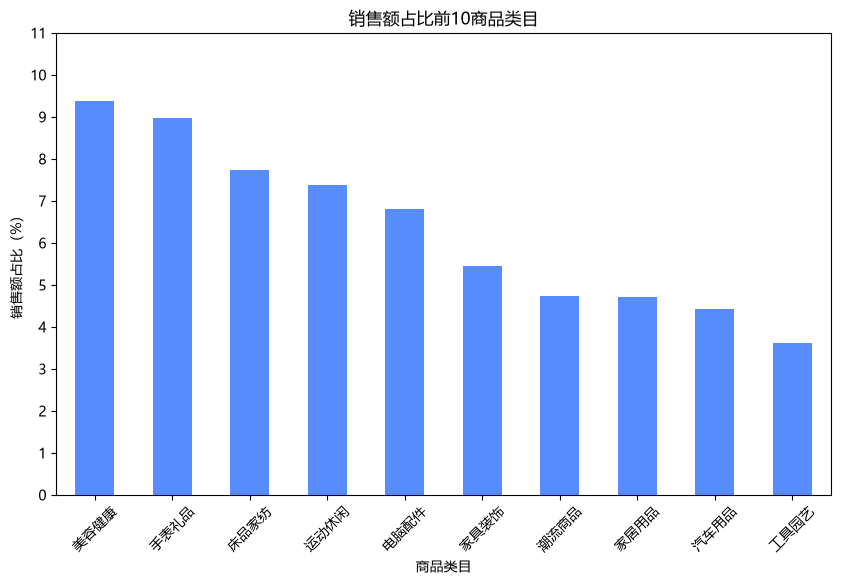

In [55]:
#绘制类别销售额占比图
category_name_map = {
    "beleza_saude": "美容健康",
    "relogios_presentes": "手表礼品",
    "cama_mesa_banho": "床品家纺",
    "esporte_lazer": "运动休闲",
    "informatica_acessorios": "电脑配件",
    "moveis_decoracao": "家具装饰",
    "cool_stuff": "潮流商品",
    "utilidades_domesticas": "家居用品",
    "automotivo": "汽车用品",
    "ferramentas_jardim": "工具园艺"
}
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False

category_sales_rate.head(10).rename(
    index = category_name_map
).plot(
    kind="bar",
    figsize = (10,6)
)
plt.title("销售额占比前10商品类目")
plt.xlabel("商品类目")
plt.ylabel("销售额占比（%）")
plt.xticks(rotation = 45)
plt.yticks(range(0,12,1))
plt.ylim(0,11)
plt.show()

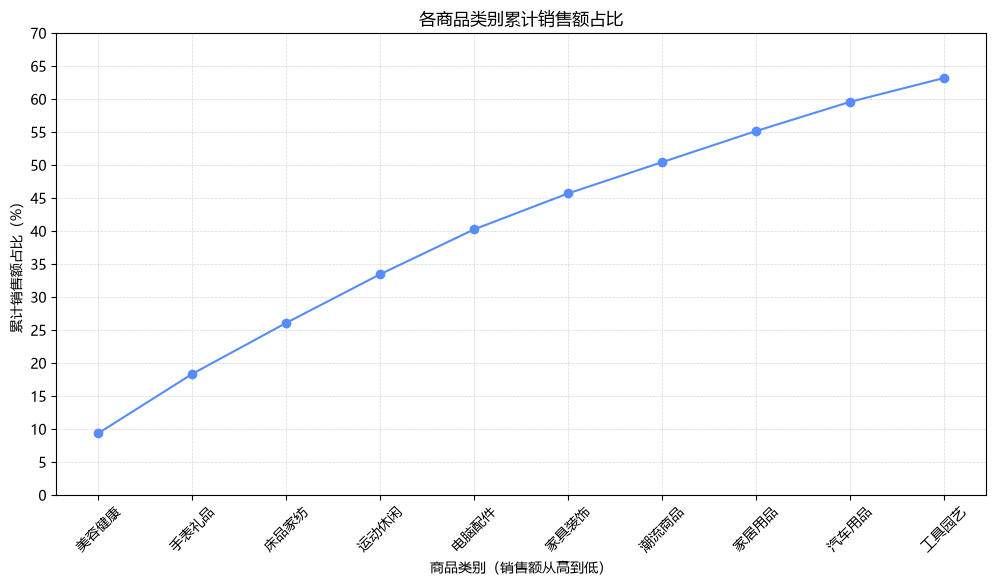

In [46]:
plt.xticks(range(10))
category_cum_rate.head(10).rename(
    index=category_name_map
).plot(
    kind="line",
    marker="o",
    figsize=(12, 6)
)

plt.title("各商品类别累计销售额占比")
plt.xlabel("商品类别（销售额从高到低）")
plt.ylabel("累计销售额占比（%）")
plt.xticks(rotation=45)
plt.grid(axis = "both",linestyle = "--",alpha = 0.5)#显示网格线
plt.ylim(0,70)
plt.yticks(range(0,71,5))
plt.show()


In [48]:
#前五个类别贡献占越40%，前十个约63%，其他则是37%左右，前10个占约六成，但还有约四层在其他，所以销售额存在一定的集中现象

np.float64(100.00000000000001)

In [ ]:
#根据以上分析，前10商品类型占60%以上销售额占比，说明销售额存在一定的集中现象；在以上现象中，很容易看出美容健康的综合评价很好，单价处于相对合理的水平，同时销量也高，因此销售额也高。
#排名第二的手表礼品的单价较高，所以销售量低于第三，但由于单价很高所以销售额更高。